<a href="https://colab.research.google.com/github/VirajKosala/Intelligent-Link-Quality-Prediction/blob/main/Intelligent_Link_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Weerathunga V.K - IT23322912


##Intelligent Link Quality Prediction and Remaining Communication Range Estimation

### Initial Model: Random Forest Classifier

**Baseline Model:** Logistic Regression


##1. Setup and Imports

In [5]:

# SECTION 01: Install Required Libraries

!pip install pandas numpy scikit-learn matplotlib seaborn joblib


In [6]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Data preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Model saving
import joblib

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [7]:

np.random.seed(42)
RANDOM_STATE = 42

print("Libraries loaded successfully.")
print("Random seed:", RANDOM_STATE)


Libraries loaded successfully.
Random seed: 42


## 2. Data Loading and Initial Inspection

In [8]:

df = pd.read_csv("/content/Link_Quality_T003_T020_CHRONOLOGICAL_MASTER.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (2982, 34)


,pc_timestamp,trial_id,device_ms,event_type,boat_id,related_boat_id,sequence_id,message_type,latitude,longitude,...,lora_snr_db,fallback_used,final_transport,final_delivery_success,ack_rtt_ms,received_transport,note,environment,test_mode,source_filename
0,2026-10-09T09:11:32.018+05:30,T004,46805,GPS_BUTTON,BOAT-001,BOAT-002,1.0,GPS_LOCATION,6.334713,80.124554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OUTDOOR,REAL_WORLD,Sea_Guardian_T004_ALL_DATA(5).csv
1,2026-10-09T09:11:32.073+05:30,T004,46856,COMM_RESULT,BOAT-001,BOAT-002,1.0,GPS_LOCATION,6.334713,80.124554,...,NaN,0.0,ESP_NOW,1.0,50.0,ESP_NOW,NaN,OUTDOOR,REAL_WORLD,Sea_Guardian_T004_ALL_DATA(5).csv
2,2026-10-09T09:11:34.941+05:30,T004,49728,GPS_BUTTON,BOAT-001,BOAT-002,2.0,GPS_LOCATION,6.334714,80.124560,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OUTDOOR,REAL_WORLD,Sea_Guardian_T004_ALL_DATA(5).csv
3,2026-10-09T09:11:34.986+05:30,T004,49769,COMM_RESULT,BOAT-001,BOAT-002,2.0,GPS_LOCATION,6.334714,80.124560,...,NaN,0.0,ESP_NOW,1.0,40.0,ESP_NOW,NaN,OUTDOOR,REAL_WORLD,Sea_Guardian_T004_ALL_DATA(5).csv
4,2026-10-09T09:11:44.100+05:30,T004,58888,GPS_BUTTON,BOAT-001,BOAT-002,3.0,GPS_LOCATION,6.334720,80.124566,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OUTDOOR,REAL_WORLD,Sea_Guardian_T004_ALL_DATA(5).csv


### Dataset Structure and Summary Statistics

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2982 entries, 0 to 2981
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   pc_timestamp             2982 non-null   object 
 1   trial_id                 2982 non-null   object 
 2   device_ms                2982 non-null   int64  
 3   event_type               2982 non-null   object 
 4   boat_id                  2982 non-null   object 
 5   related_boat_id          2459 non-null   object 
 6   sequence_id              2459 non-null   float64
 7   message_type             2459 non-null   object 
 8   latitude                 2964 non-null   float64
 9   longitude                2964 non-null   float64
 10  gps_valid                2982 non-null   int64  
 11  peer_latitude            1168 non-null   float64
 12  peer_longitude           1168 non-null   float64
 13  distance_m               1164 non-null   float64
 14  peer_gps_age_ms         

In [10]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pc_timestamp,2982,2982,2026-10-12T14:14:10.577+05:30,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trial_id,2982,13,T018,1112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_ms,2982.0,NaN,NaN,NaN,774780.711268,929849.482087,2643.0,257576.25,544625.5,939321.0,8364024.0
event_type,2982,13,GPS_BUTTON,1177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
boat_id,2982,2,BOAT-001,2952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
related_boat_id,2459,2,BOAT-002,2381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sequence_id,2459.0,NaN,NaN,NaN,191.854006,201.782497,1.0,34.0,96.0,324.5,689.0
message_type,2459,5,GPS_LOCATION,2380,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,2964.0,NaN,NaN,NaN,6.659009,0.287677,6.330885,6.334758,6.913823,6.914307,6.915251
longitude,2964.0,NaN,NaN,NaN,80.042178,0.07417,79.972876,79.976278,79.977811,80.124577,80.129575


In [11]:
display(df.describe())

,device_ms,sequence_id,latitude,longitude,gps_valid,peer_latitude,peer_longitude,distance_m,peer_gps_age_ms,water_ao_raw,water_do_raw,countdown_remaining_sec,buzzer_active,espnow_rssi_dbm,espnow_ack_success,lora_rssi_dbm,lora_snr_db,fallback_used,final_delivery_success,ack_rtt_ms
count,2.982000e+03,2459.000000,2964.000000,2964.000000,2982.000000,1168.000000,1168.000000,1164.000000,1168.000000,2982.000000,2982.000000,301.000000,2982.000000,174.000000,171.000000,826.000000,826.000000,1174.000000,1174.000000,962.000000
mean,7.747807e+05,191.854006,6.659009,80.042178,0.993964,6.721518,80.023567,295.845017,14809.323630,3428.024816,0.856808,32.299003,0.015426,-82.637931,0.888889,-91.297821,5.354116,0.870528,0.819421,378.165281
std,9.298495e+05,201.782497,0.287677,0.074170,0.077471,0.273497,0.071446,173.006488,50156.697818,1212.523941,0.350328,17.575655,0.123260,9.218663,0.315193,7.193325,4.619596,0.335865,0.384833,514.916855
min,2.643000e+03,1.000000,6.330885,79.972876,0.000000,6.334556,79.972281,3.700000,0.000000,0.000000,0.000000,1.000000,0.000000,-92.000000,0.000000,-110.000000,-10.000000,0.000000,0.000000,16.000000
25%,2.575762e+05,34.000000,6.334758,79.976278,1.000000,6.334655,79.973016,154.650000,0.000000,3100.000000,1.000000,18.000000,0.000000,-86.000000,1.000000,-97.000000,2.500000,1.000000,1.000000,267.000000
50%,5.446255e+05,96.000000,6.913823,79.977811,1.000000,6.914680,79.973188,344.800000,0.000000,4095.000000,1.000000,32.000000,0.000000,-84.000000,1.000000,-90.000000,7.500000,1.000000,1.000000,268.000000
75%,9.393210e+05,324.500000,6.914307,80.124577,1.000000,6.914713,80.124627,408.525000,0.000000,4095.000000,1.000000,48.000000,0.000000,-83.000000,1.000000,-85.000000,8.700000,1.000000,1.000000,268.000000
max,8.364024e+06,689.000000,6.915251,80.129575,1.000000,6.915198,80.124660,631.300000,579172.000000,4095.000000,1.000000,60.000000,1.000000,-30.000000,1.000000,-70.000000,11.200000,1.000000,1.000000,3056.000000


### Missing Values and Duplicate Records

In [12]:

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_values)


,Missing Count,Missing Percentage
pc_timestamp,0,0.00
trial_id,0,0.00
device_ms,0,0.00
event_type,0,0.00
boat_id,0,0.00
related_boat_id,523,17.54
sequence_id,523,17.54
message_type,523,17.54
latitude,18,0.60
longitude,18,0.60


### Duplicate Records

In [13]:

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)


Total duplicate records: 0



## 3. Exploratory Data Analysis (EDA)

The communication data is analyzed to examine event distributions, transmission outcomes, signal measurements, and distance-related patterns before model development.


In [14]:

event_counts = df["event_type"].value_counts()

display(event_counts.to_frame("Count"))

comm_df = df[df["event_type"] == "COMM_RESULT"].copy()

print("Total records:", len(df))
print("Communication records:", len(comm_df))


,Count
event_type,
GPS_BUTTON,1177
COMM_RESULT,1174
WATER_SAMPLE,523
GPS_RECEIVED,29
EMERGENCY_CLEAR_ACK,22
WATER_DRY,15
WATER_WET,14
EMERGENCY_ACK_RECEIVED,8
EMERGENCY_ACTIVE,6


Total records: 2982
Communication records: 1174



### Communication Event Distribution

The frequency of different recorded event types is visualized to understand the composition of the dataset.


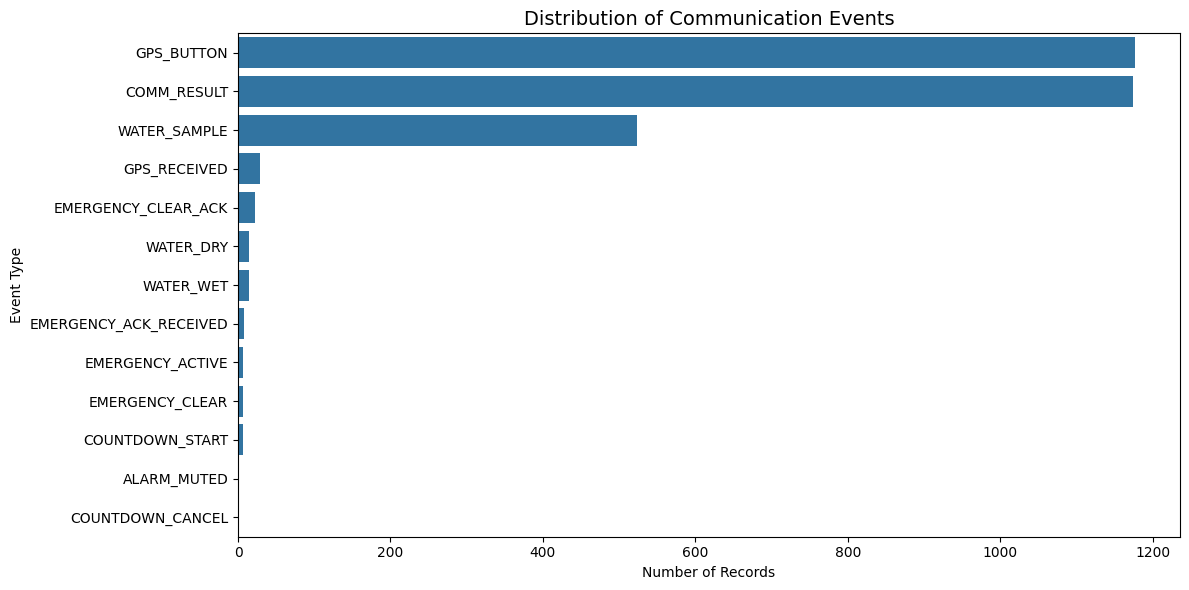

In [15]:

plt.figure(figsize=(12, 6))

sns.barplot(
    x=event_counts.values,
    y=event_counts.index
)

plt.title("Distribution of Communication Events", fontsize=14)
plt.xlabel("Number of Records")
plt.ylabel("Event Type")
plt.tight_layout()
plt.show()



### Communication Outcomes by Transport

The distribution of confirmed communication outcomes is examined to understand the use of ESP-NOW, LoRa, and unsuccessful acknowledgment attempts.


,Count
final_transport,
ESP_NOW,152
LORA,810
NONE,212


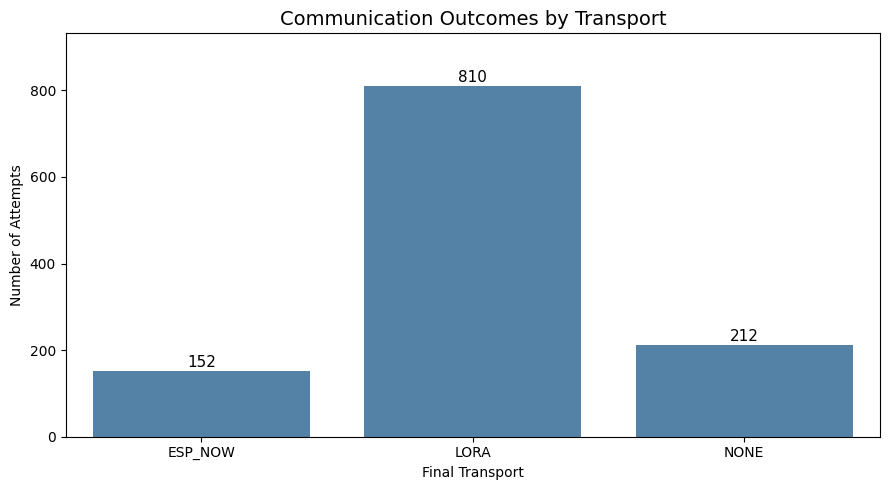

In [16]:

transport_counts = comm_df["final_transport"].value_counts().reindex(
    ["ESP_NOW", "LORA", "NONE"], fill_value=0
)

display(transport_counts.to_frame("Count"))

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=transport_counts.index,
    y=transport_counts.values,
    color="steelblue"
)

for i, count in enumerate(transport_counts.values):
    ax.text(i, count + 8, str(count), ha="center", fontsize=11)

plt.title("Communication Outcomes by Transport", fontsize=14)
plt.xlabel("Final Transport")
plt.ylabel("Number of Attempts")
plt.ylim(0, transport_counts.max() * 1.15)
plt.tight_layout()
plt.show()



### Distance vs Communication Outcomes

The relationship between communication distance and confirmed transmission outcomes is examined using available GPS measurements.


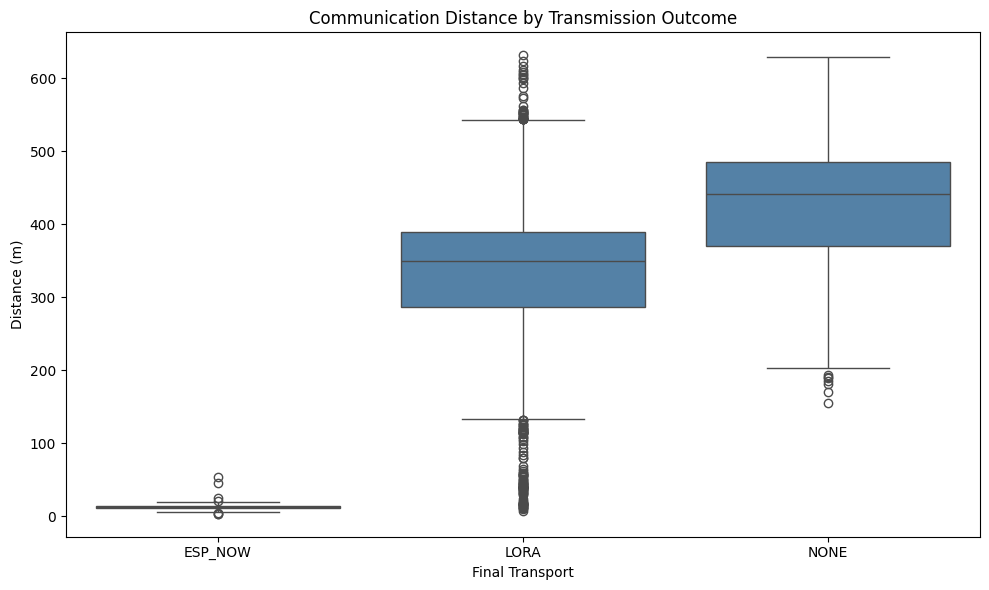

,count,min,median,mean,max
final_transport,,,,,
ESP_NOW,109,3.7,12.6,13.28,53.9
LORA,802,7.6,349.4,330.55,631.3
NONE,96,155.5,442.0,422.51,628.5


Records with usable distance: 1007


In [17]:

distance_df = comm_df.copy()

distance_df["distance_m"] = pd.to_numeric(
    distance_df["distance_m"], errors="coerce"
)

distance_df["peer_gps_age_ms"] = pd.to_numeric(
    distance_df["peer_gps_age_ms"], errors="coerce"
)

distance_df = distance_df[
    distance_df["distance_m"].notna() &
    distance_df["peer_gps_age_ms"].between(0, 30000)
].copy()

transport_order = ["ESP_NOW", "LORA", "NONE"]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=distance_df,
    x="final_transport",
    y="distance_m",
    order=transport_order,
    color="steelblue"
)

plt.title("Communication Distance by Transmission Outcome")
plt.xlabel("Final Transport")
plt.ylabel("Distance (m)")
plt.tight_layout()
plt.show()

display(
    distance_df.groupby("final_transport")["distance_m"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(2)
    .reindex(transport_order)
)

print("Records with usable distance:", len(distance_df))



### Distance vs LoRa Signal Strength (RSSI)

The relationship between communication distance and LoRa received signal strength (RSSI) is examined to identify variations in signal quality.


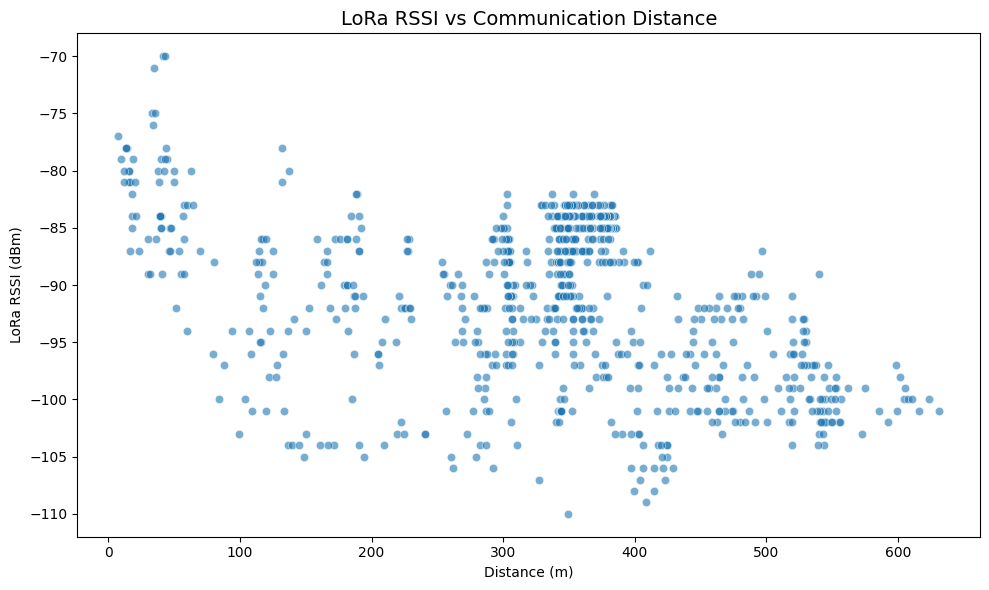

LoRa records analyzed: 802


,distance_m,lora_rssi_dbm
count,802.00,802.00
mean,330.55,-91.29
std,134.24,7.16
min,7.60,-110.00
25%,286.73,-97.00
50%,349.40,-90.00
75%,389.15,-85.00
max,631.30,-70.00


In [18]:

lora_df = distance_df[
    (distance_df["final_transport"] == "LORA") &
    (distance_df["lora_rssi_dbm"].notna())
].copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lora_df,
    x="distance_m",
    y="lora_rssi_dbm",
    alpha=0.6
)

plt.title("LoRa RSSI vs Communication Distance", fontsize=14)
plt.xlabel("Distance (m)")
plt.ylabel("LoRa RSSI (dBm)")
plt.tight_layout()
plt.show()

print("LoRa records analyzed:", len(lora_df))

display(
    lora_df[["distance_m", "lora_rssi_dbm"]]
    .describe()
    .round(2)
)



### Distance vs LoRa Signal-to-Noise Ratio (SNR)

The relationship between communication distance and LoRa SNR is analyzed to examine signal quality variations across different distances.


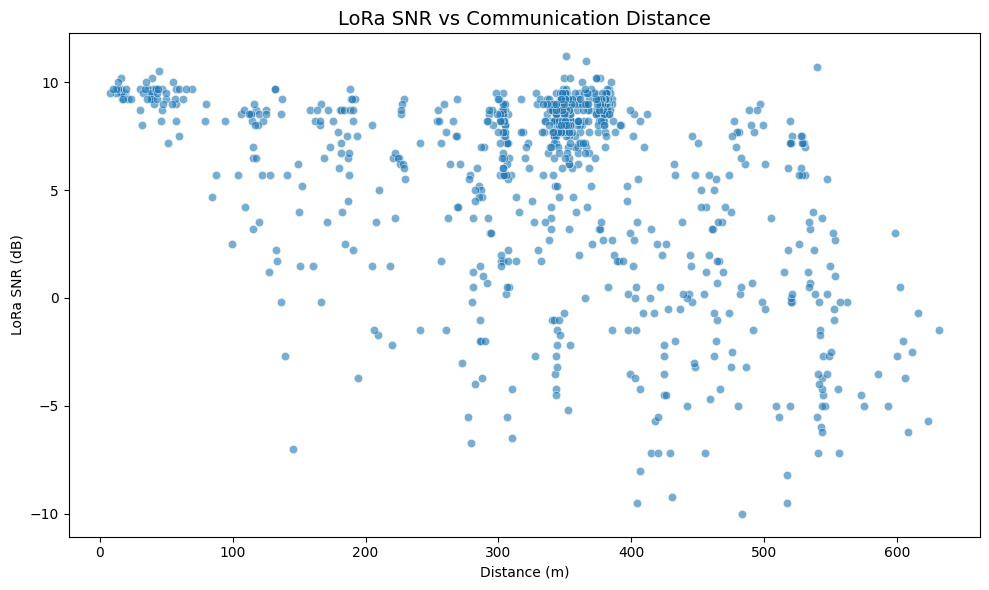

LoRa records analyzed: 802


,distance_m,lora_snr_db
count,802.00,802.00
mean,330.55,5.39
std,134.24,4.59
min,7.60,-10.00
25%,286.73,2.70
50%,349.40,7.50
75%,389.15,8.70
max,631.30,11.20


In [19]:

snr_df = lora_df.dropna(subset=["lora_snr_db"]).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=snr_df,
    x="distance_m",
    y="lora_snr_db",
    alpha=0.6
)

plt.title("LoRa SNR vs Communication Distance", fontsize=14)
plt.xlabel("Distance (m)")
plt.ylabel("LoRa SNR (dB)")
plt.tight_layout()
plt.show()

print("LoRa records analyzed:", len(snr_df))

display(
    snr_df[["distance_m", "lora_snr_db"]]
    .describe()
    .round(2)
)



### ACK Success Rate by Distance

Confirmed acknowledgment rates are analyzed across distance intervals to examine communication reliability patterns in the hybrid ESP-NOW and LoRa system.


,Distance Range,Attempts,Confirmed ACKs,ACK Rate (%)
0,"[0, 100)",176,176.0,100.00
1,"[100, 200)",82,75.0,91.46
2,"[200, 300)",85,80.0,94.12
3,"[300, 400)",410,391.0,95.37
4,"[400, 500)",152,104.0,68.42
5,"[500, 600)",89,77.0,86.52
6,"[600, 700)",13,8.0,61.54


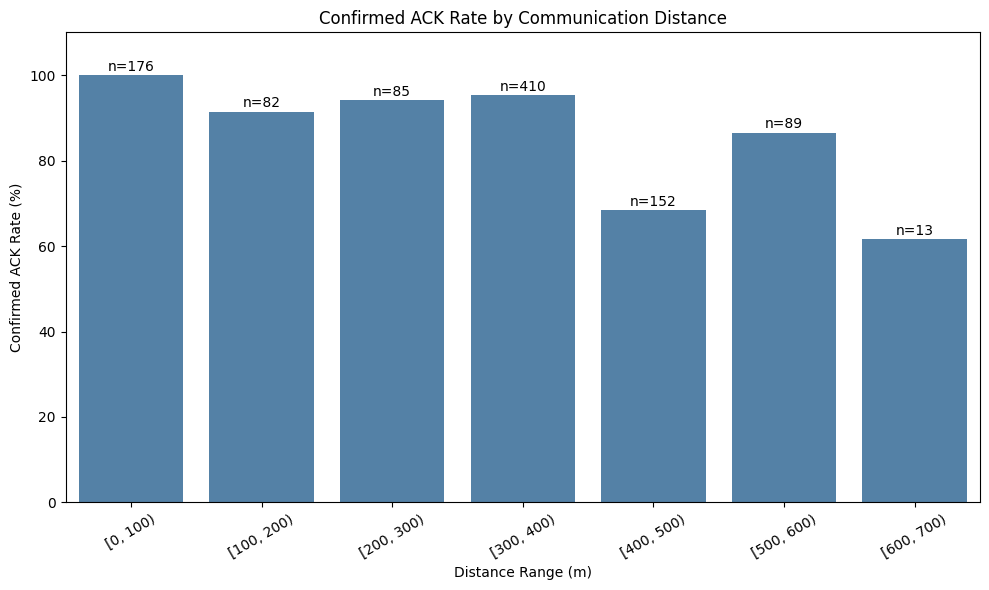

In [20]:

ack_distance = distance_df[
    distance_df["final_delivery_success"].isin([0, 1])
].copy()

ack_distance["distance_range"] = pd.cut(
    ack_distance["distance_m"],
    bins=np.arange(0, 701, 100),
    right=False
)

ack_summary = (
    ack_distance.groupby("distance_range", observed=True)
    ["final_delivery_success"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

ack_summary.columns = [
    "Distance Range", "Attempts", "Confirmed ACKs", "ACK Rate"
]

ack_summary["ACK Rate (%)"] = (
    ack_summary["ACK Rate"] * 100
).round(2)

display(
    ack_summary[
        ["Distance Range", "Attempts", "Confirmed ACKs", "ACK Rate (%)"]
    ]
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=ack_summary,
    x="Distance Range",
    y="ACK Rate (%)",
    color="steelblue"
)

for i, row in ack_summary.iterrows():
    ax.text(
        i,
        row["ACK Rate (%)"] + 1,
        f'n={row["Attempts"]}',
        ha="center",
        fontsize=10
    )

plt.title("Confirmed ACK Rate by Communication Distance")
plt.xlabel("Distance Range (m)")
plt.ylabel("Confirmed ACK Rate (%)")
plt.ylim(0, 110)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



### Communication Outcomes Across Trials

The distribution of confirmed ACK outcomes across experimental trials is examined to identify class imbalance and support trial-based model evaluation.


,No ACK,Confirmed ACK,Total
trial_id,,,
T003,2,0,2
T004,34,22,56
T005,18,1,19
T008,33,65,98
T009,0,38,38
T010,0,75,75
T012,64,49,113
T013,0,3,3
T014,0,1,1


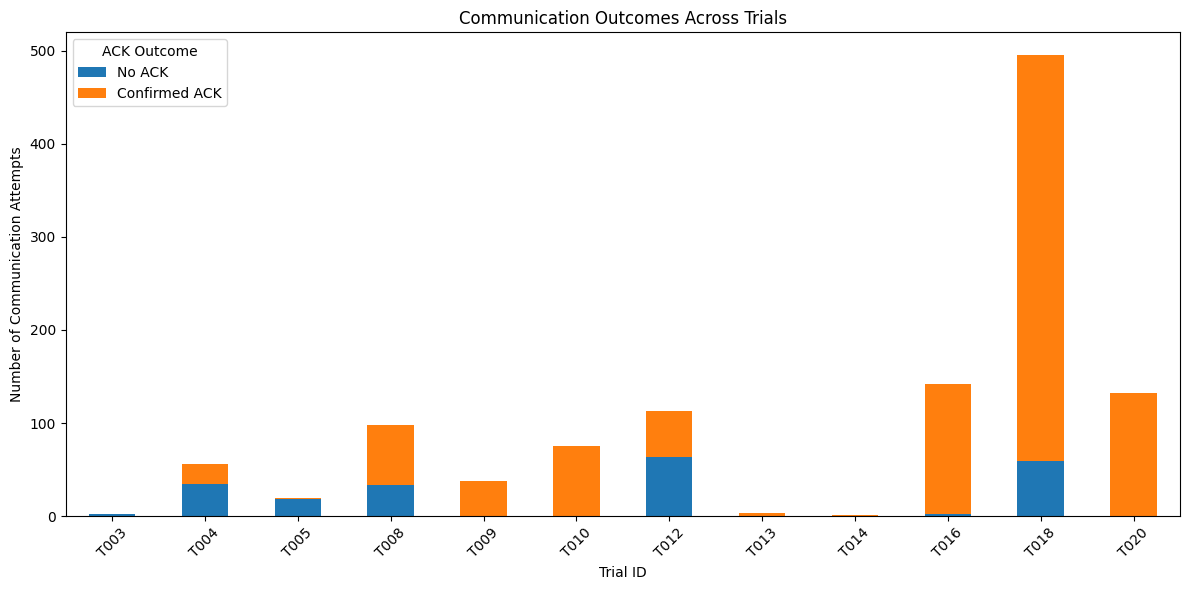

In [21]:

trial_summary = pd.crosstab(
    comm_df["trial_id"].astype(str).str.strip().str.rstrip("\\"),
    comm_df["final_delivery_success"]
)

trial_summary = trial_summary.reindex(columns=[0.0, 1.0], fill_value=0)
trial_summary.columns = ["No ACK", "Confirmed ACK"]

trial_summary["Total"] = trial_summary.sum(axis=1)
trial_summary = trial_summary.sort_index()

display(trial_summary)

trial_summary[["No ACK", "Confirmed ACK"]].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Communication Outcomes Across Trials")
plt.xlabel("Trial ID")
plt.ylabel("Number of Communication Attempts")
plt.xticks(rotation=45)
plt.legend(title="ACK Outcome")
plt.tight_layout()
plt.show()



### Signal Measurement Availability

The availability of GPS distance, RSSI, and SNR measurements is examined across confirmed and unconfirmed communication outcomes to assess feature completeness.


,distance_m,espnow_rssi_dbm,lora_rssi_dbm,lora_snr_db
final_delivery_success,,,,
No ACK,86.32,0.0,0.0,0.0
Confirmed ACK,99.17,15.8,84.2,84.2


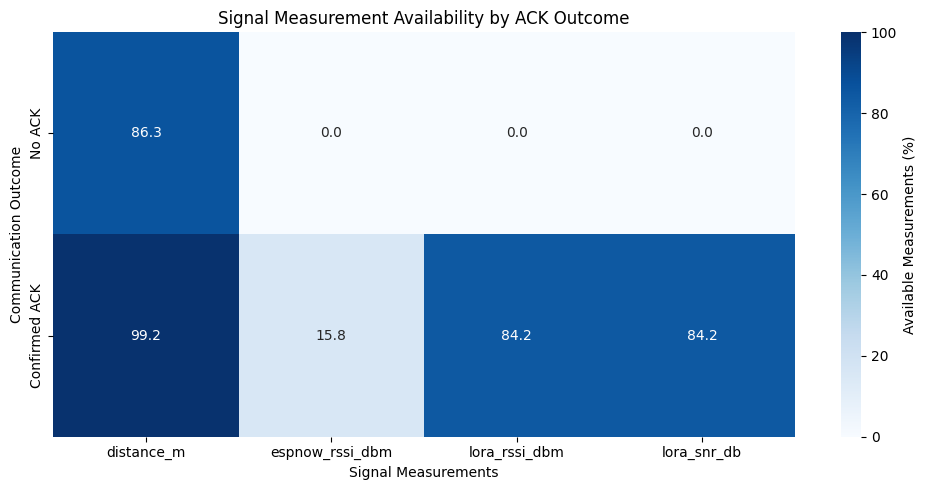

In [22]:

signal_columns = [
    "distance_m",
    "espnow_rssi_dbm",
    "lora_rssi_dbm",
    "lora_snr_db"
]

availability = (
    comm_df[signal_columns]
    .notna()
    .groupby(comm_df["final_delivery_success"])
    .mean()
    .mul(100)
    .round(2)
)

availability.index = availability.index.map({
    0.0: "No ACK",
    1.0: "Confirmed ACK"
})

display(availability)

plt.figure(figsize=(10, 5))

sns.heatmap(
    availability,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Available Measurements (%)"}
)

plt.title("Signal Measurement Availability by ACK Outcome")
plt.xlabel("Signal Measurements")
plt.ylabel("Communication Outcome")
plt.tight_layout()
plt.show()



## 4. Data Cleaning

Communication records are prepared for machine learning by checking data types, standardizing trial identifiers, and identifying incomplete measurements. Original records are preserved.


In [23]:

clean_df = comm_df.copy()

clean_df["trial_id"] = (
    clean_df["trial_id"]
    .astype(str)
    .str.strip()
    .str.rstrip("\\")
)

clean_df["pc_timestamp"] = pd.to_datetime(
    clean_df["pc_timestamp"],
    errors="coerce",
    utc=True
)

numeric_columns = [
    "distance_m",
    "peer_gps_age_ms",
    "espnow_rssi_dbm",
    "lora_rssi_dbm",
    "lora_snr_db",
    "final_delivery_success"
]

clean_df[numeric_columns] = clean_df[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

print("Communication records:", len(clean_df))
print("Invalid timestamps:", clean_df["pc_timestamp"].isna().sum())
print("Unique trials:", clean_df["trial_id"].nunique())

display(clean_df["trial_id"].value_counts().sort_index())


Communication records: 1174
Invalid timestamps: 0
Unique trials: 12


,count
trial_id,
T003,2
T004,56
T005,19
T008,98
T009,38
T010,75
T012,113
T013,3
T014,1



### GPS Distance Quality Assessment

GPS distance measurements are examined for missing, invalid, and outdated values before feature preparation.


In [24]:

clean_df["gps_valid"] = pd.to_numeric(
    clean_df["gps_valid"], errors="coerce"
)

clean_df["distance_available"] = (
    clean_df["distance_m"].notna() &
    (clean_df["distance_m"] >= 0)
)

clean_df["gps_fresh"] = clean_df["peer_gps_age_ms"].between(
    0, 30000
)

clean_df["distance_usable"] = (
    clean_df["distance_available"] &
    clean_df["gps_fresh"] &
    (clean_df["gps_valid"] == 1)
)

print("Total Communication Records:", len(clean_df))
print("Missing Distance:", clean_df["distance_m"].isna().sum())
print("Invalid Negative Distance:", (clean_df["distance_m"] < 0).sum())
print("GPS Age Above 30 Seconds:", (clean_df["peer_gps_age_ms"] > 30000).sum())
print("Usable Distance Records:", clean_df["distance_usable"].sum())
print("Unusable Distance Records:", (~clean_df["distance_usable"]).sum())


Total Communication Records: 1174
Missing Distance: 37
Invalid Negative Distance: 0
GPS Age Above 30 Seconds: 130
Usable Distance Records: 1007
Unusable Distance Records: 167



### ACK Target Validation

Communication outcomes are examined to verify the binary target variable used for predicting acknowledgment reliability.


In [25]:

print("ACK Outcome Distribution")
display(
    clean_df["final_delivery_success"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

print("Missing Target Values:",
      clean_df["final_delivery_success"].isna().sum())

print("Invalid Target Values:",
      (~clean_df["final_delivery_success"].isin([0, 1])).sum())

print("\nSignal Measurement Availability")
display(
    clean_df[
        ["espnow_rssi_dbm", "lora_rssi_dbm", "lora_snr_db"]
    ].notna().sum().to_frame("Available Records")
)


ACK Outcome Distribution


,Count
final_delivery_success,
0.0,212
1.0,962


Missing Target Values: 0
Invalid Target Values: 0

Signal Measurement Availability


,Available Records
espnow_rssi_dbm,152
lora_rssi_dbm,810
lora_snr_db,810



### Communication Outcome Consistency

The acknowledgment outcomes and final transport values are checked for consistency before preparing the target variable for model training.


In [26]:

clean_df["final_transport"] = (
    clean_df["final_transport"]
    .astype("string")
    .str.strip()
    .str.upper()
)

transport_summary = pd.crosstab(
    clean_df["final_transport"],
    clean_df["final_delivery_success"]
)

display(transport_summary)

valid_outcomes = (
    ((clean_df["final_delivery_success"] == 1) &
     clean_df["final_transport"].isin(["ESP_NOW", "LORA"])) |
    ((clean_df["final_delivery_success"] == 0) &
     (clean_df["final_transport"] == "NONE"))
)

print("Consistent Records:", valid_outcomes.sum())
print("Inconsistent Records:", (~valid_outcomes).sum())


final_delivery_success,0.0,1.0
final_transport,,
ESP_NOW,0,152
LORA,0,810
NONE,212,0


Consistent Records: 1174
Inconsistent Records: 0



### Final Data Preparation

The validated communication records are ordered chronologically within each trial, and the binary ACK target is prepared for machine learning.


In [27]:

clean_df = clean_df.sort_values(
    ["trial_id", "pc_timestamp", "device_ms"],
    kind="stable"
).reset_index(drop=True)

clean_df["ack_target"] = clean_df["final_delivery_success"].astype(int)

print("Cleaned records:", len(clean_df))
print("Total trials:", clean_df["trial_id"].nunique())
print("Missing targets:", clean_df["ack_target"].isna().sum())
print("Duplicate records:", clean_df.duplicated().sum())

display(clean_df["ack_target"].value_counts().sort_index())


Cleaned records: 1174
Total trials: 12
Missing targets: 0
Duplicate records: 0


,count
ack_target,
0,212
1,962



## 5. Trial-Based Data Splitting

The communication dataset is divided into training, validation, and testing sets based on experimental trials to minimize data leakage and evaluate model generalization.


In [28]:

trial_summary = clean_df.groupby("trial_id").agg(
    Total_Records=("ack_target", "size"),
    Successful_ACK=("ack_target", "sum"),
    Start_Time=("pc_timestamp", "min"),
    End_Time=("pc_timestamp", "max")
)

trial_summary["Failed_ACK"] = (
    trial_summary["Total_Records"] -
    trial_summary["Successful_ACK"]
)

trial_summary["Success_Rate"] = (
    trial_summary["Successful_ACK"] /
    trial_summary["Total_Records"] * 100
).round(2)

display(trial_summary.sort_index())


,Total_Records,Successful_ACK,Start_Time,End_Time,Failed_ACK,Success_Rate
trial_id,,,,,,
T003,2,0,2026-10-09 03:51:33.694000+00:00,2026-10-09 03:51:37.105000+00:00,2,0.00
T004,56,22,2026-10-09 03:41:32.073000+00:00,2026-10-09 03:52:54.935000+00:00,34,39.29
T005,19,1,2026-10-09 03:53:08.094000+00:00,2026-10-09 03:55:35.151000+00:00,18,5.26
T008,98,65,2026-10-09 04:04:47.084000+00:00,2026-10-09 04:19:14.569000+00:00,33,66.33
T009,38,38,2026-10-09 04:41:09.435000+00:00,2026-10-09 04:56:34.617000+00:00,0,100.00
T010,75,75,2026-10-09 04:59:22.541000+00:00,2026-10-09 07:18:43.632000+00:00,0,100.00
T012,113,49,2026-10-09 07:49:19.532000+00:00,2026-10-09 08:04:11.972000+00:00,64,43.36
T013,3,3,2026-10-12 06:43:17.175000+00:00,2026-10-12 06:43:34.497000+00:00,0,100.00
T014,1,1,2026-10-12 07:48:55.307000+00:00,2026-10-12 07:48:55.307000+00:00,0,100.00



### Trial Timeline Analysis

The chronological sequence and time gaps between experimental trials are examined to identify overlapping or closely related recording sessions before data splitting.


In [29]:

trial_timeline = trial_summary.reset_index().sort_values(
    "Start_Time"
).copy()

previous_end = trial_timeline["End_Time"].cummax().shift(1)

trial_timeline["Gap_Minutes"] = (
    (trial_timeline["Start_Time"] - previous_end)
    .dt.total_seconds() / 60
).round(2)

trial_timeline["Start_Local"] = (
    trial_timeline["Start_Time"].dt.tz_convert("Asia/Colombo")
)

trial_timeline["End_Local"] = (
    trial_timeline["End_Time"].dt.tz_convert("Asia/Colombo")
)

display(
    trial_timeline[
        ["trial_id", "Total_Records", "Start_Local",
         "End_Local", "Gap_Minutes"]
    ]
)


,trial_id,Total_Records,Start_Local,End_Local,Gap_Minutes
1,T004,56,2026-10-09 09:11:32.073000+05:30,2026-10-09 09:22:54.935000+05:30,NaN
0,T003,2,2026-10-09 09:21:33.694000+05:30,2026-10-09 09:21:37.105000+05:30,-1.35
2,T005,19,2026-10-09 09:23:08.094000+05:30,2026-10-09 09:25:35.151000+05:30,0.22
3,T008,98,2026-10-09 09:34:47.084000+05:30,2026-10-09 09:49:14.569000+05:30,9.20
4,T009,38,2026-10-09 10:11:09.435000+05:30,2026-10-09 10:26:34.617000+05:30,21.91
5,T010,75,2026-10-09 10:29:22.541000+05:30,2026-10-09 12:48:43.632000+05:30,2.80
6,T012,113,2026-10-09 13:19:19.532000+05:30,2026-10-09 13:34:11.972000+05:30,30.60
7,T013,3,2026-10-12 12:13:17.175000+05:30,2026-10-12 12:13:34.497000+05:30,4239.09
8,T014,1,2026-10-12 13:18:55.307000+05:30,2026-10-12 13:18:55.307000+05:30,65.35
9,T016,142,2026-10-12 13:20:55.586000+05:30,2026-10-12 13:38:12.445000+05:30,2.00



### Recording Source Verification

Original recording files are examined to identify relationships between experimental trials and support leakage-aware dataset partitioning.


In [30]:

source_summary = clean_df.groupby(
    ["trial_id", "source_filename"],
    dropna=False
).agg(
    Records=("ack_target", "size"),
    Confirmed_ACK=("ack_target", "sum"),
    Start_Time=("pc_timestamp", "min"),
    End_Time=("pc_timestamp", "max")
).reset_index()

source_summary["No_ACK"] = (
    source_summary["Records"] - source_summary["Confirmed_ACK"]
)

display(
    source_summary[
        ["trial_id", "source_filename", "Records",
         "Confirmed_ACK", "No_ACK", "Start_Time", "End_Time"]
    ].sort_values(["Start_Time", "trial_id"])
)


,trial_id,source_filename,Records,Confirmed_ACK,No_ACK,Start_Time,End_Time
1,T004,Sea_Guardian_T004_ALL_DATA(5).csv,47,22,25,2026-10-09 03:41:32.073000+00:00,2026-10-09 03:46:45.491000+00:00
0,T003,Sea_Guardian_T003_ALL_DATA(3).csv,2,0,2,2026-10-09 03:51:33.694000+00:00,2026-10-09 03:51:37.105000+00:00
2,T004,Sea_Guardian_T004__ALL_DATA(3).csv,9,0,9,2026-10-09 03:52:16.134000+00:00,2026-10-09 03:52:54.935000+00:00
3,T005,Sea_Guardian_T005__ALL_DATA(3).csv,19,1,18,2026-10-09 03:53:08.094000+00:00,2026-10-09 03:55:35.151000+00:00
4,T008,Sea_Guardian_T008__ALL_DATA(3).csv,98,65,33,2026-10-09 04:04:47.084000+00:00,2026-10-09 04:19:14.569000+00:00
5,T009,Sea_Guardian_T009__ALL_DATA(2).csv,38,38,0,2026-10-09 04:41:09.435000+00:00,2026-10-09 04:56:34.617000+00:00
6,T010,Sea_Guardian_T010_ALL_DATA(2).csv,75,75,0,2026-10-09 04:59:22.541000+00:00,2026-10-09 07:18:43.632000+00:00
7,T012,Sea_Guardian_T012_ALL_DATA(2).csv,113,49,64,2026-10-09 07:49:19.532000+00:00,2026-10-09 08:04:11.972000+00:00
8,T013,Sea_Guardian_T013_ALL_DATA(2).csv,3,3,0,2026-10-12 06:43:17.175000+00:00,2026-10-12 06:43:34.497000+00:00
9,T014,Sea_Guardian_T014_ALL_DATA(2).csv,1,1,0,2026-10-12 07:48:55.307000+00:00,2026-10-12 07:48:55.307000+00:00



### Distance Coverage Analysis

The distribution of communication distances across experimental trials is analyzed to identify short-, medium-, and long-distance observations. This analysis supports representative trial-based data splitting while minimizing data leakage.


In [31]:

distance_analysis = clean_df.copy()

distance_analysis["usable_distance"] = (
    distance_analysis["distance_m"].where(
        distance_analysis["distance_usable"]
    )
)

distance_bins = [0, 100, 300, 500, np.inf]
distance_labels = ["0-100m", "100-300m", "300-500m", "500m+"]

distance_analysis["distance_group"] = pd.cut(
    distance_analysis["usable_distance"],
    bins=distance_bins,
    labels=distance_labels,
    right=False
)

distance_summary = distance_analysis.groupby("trial_id").agg(
    Total_Records=("ack_target", "size"),
    Usable_Distances=("usable_distance", "count"),
    Min_Distance=("usable_distance", "min"),
    Median_Distance=("usable_distance", "median"),
    Max_Distance=("usable_distance", "max"),
    No_ACK=("ack_target", lambda x: (x == 0).sum())
)

distance_counts = pd.crosstab(
    distance_analysis["trial_id"],
    distance_analysis["distance_group"]
).reindex(columns=distance_labels, fill_value=0)

distance_summary = distance_summary.join(distance_counts)

distance_summary[
    ["Min_Distance", "Median_Distance", "Max_Distance"]
] = distance_summary[
    ["Min_Distance", "Median_Distance", "Max_Distance"]
].round(2)

display(distance_summary)


,Total_Records,Usable_Distances,Min_Distance,Median_Distance,Max_Distance,No_ACK,0-100m,100-300m,300-500m,500m+
trial_id,,,,,,,,,,
T003,2,0,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN
T004,56,29,11.5,99.50,225.4,34,15.0,14.0,0.0,0.0
T005,19,0,NaN,NaN,NaN,18,NaN,NaN,NaN,NaN
T008,98,46,16.5,178.60,510.5,33,18.0,12.0,15.0,1.0
T009,38,38,12.3,14.50,17.4,0,38.0,0.0,0.0,0.0
T010,75,65,3.7,11.50,16.9,0,65.0,0.0,0.0,0.0
T012,113,74,8.9,355.35,475.5,64,11.0,21.0,42.0,0.0
T013,3,0,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN
T014,1,0,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN



### Distance-Based ACK Distribution Analysis

The ACK success and failure distributions are examined across distance ranges and experimental trials to evaluate class coverage before selecting the training, validation, and testing partitions.



In [32]:

ack_distance_summary = pd.crosstab(
    index=[
        distance_analysis["trial_id"],
        distance_analysis["distance_group"]
    ],
    columns=distance_analysis["ack_target"]
).reindex(columns=[0, 1], fill_value=0)

ack_distance_summary.columns = ["No_ACK", "Confirmed_ACK"]

ack_distance_summary["Total"] = (
    ack_distance_summary["No_ACK"] +
    ack_distance_summary["Confirmed_ACK"]
)

ack_distance_summary["ACK_Rate_Percentage"] = (
    ack_distance_summary["Confirmed_ACK"] /
    ack_distance_summary["Total"] * 100
).round(2)

display(
    ack_distance_summary[
        ack_distance_summary["Total"] > 0
    ]
)


No_ACK  Confirmed_ACK  Total  ACK_Rate_Percentage
trial_id distance_group                                                   
T004     0-100m               0             15     15               100.00
         100-300m             7              7     14                50.00
T008     0-100m               0             18     18               100.00
         100-300m             1             11     12                91.67
         300-500m             6              9     15                60.00
         500m+                1              0      1                 0.00
T009     0-100m               0             38     38               100.00
T010     0-100m               0             65     65               100.00
T012     0-100m               0             11     11               100.00
         100-300m             2             19     21                90.48
         300-500m            23             19     42                45.24
T016     0-100m               0             29     29               100.00
         100-300m             2             99    101                98.02
         300-500m             0              5      5               100.00
T018     300-500m            38            350    388                90.21
         500m+               16             84    100                84.00
T020     100-300m             0             19     19               100.00
         300-500m             0            112    112               100.00
         500m+                0              1      1               100.00


### Dataset Partitioning and Coverage Verification

The communication records are divided into training, validation, and testing datasets using experimental trial groups. Class distributions and distance coverage are verified to identify limitations in the evaluation dataset.


In [33]:

train_trials = ["T003", "T004", "T005", "T013", "T014", "T016", "T018", "T020"]
val_trials = ["T008", "T010"]
test_trials = ["T009", "T012"]

trial_groups = {
    "Training": train_trials,
    "Validation": val_trials,
    "Testing": test_trials
}

trial_assignment = {
    trial: group
    for group, trials in trial_groups.items()
    for trial in trials
}

split_df = clean_df.copy()
split_df["Dataset"] = split_df["trial_id"].map(trial_assignment)

assert split_df["Dataset"].notna().all()
assert len(trial_assignment) == sum(len(t) for t in trial_groups.values())

train_df = split_df[split_df["Dataset"] == "Training"].copy()
val_df = split_df[split_df["Dataset"] == "Validation"].copy()
test_df = split_df[split_df["Dataset"] == "Testing"].copy()

split_summary = split_df.groupby("Dataset").agg(
    Records=("ack_target", "size"),
    Confirmed_ACK=("ack_target", "sum"),
    No_ACK=("ack_target", lambda x: (x == 0).sum())
)

split_summary["Percentage"] = (
    split_summary["Records"] / len(split_df) * 100
).round(2)

display(split_summary.reindex(["Training", "Validation", "Testing"]))

split_df["Distance_Group"] = pd.cut(
    split_df["distance_m"].where(split_df["distance_usable"]),
    bins=[0, 100, 300, 500, np.inf],
    labels=["0-100m", "100-300m", "300-500m", "500m+"],
    right=False
).astype("object").fillna("GPS Unavailable")

distance_coverage = pd.crosstab(
    split_df["Dataset"],
    split_df["Distance_Group"]
)

distance_coverage = distance_coverage.reindex(
    index=["Training", "Validation", "Testing"],
    columns=["0-100m", "100-300m", "300-500m", "500m+", "GPS Unavailable"],
    fill_value=0
)

display(distance_coverage)


,Records,Confirmed_ACK,No_ACK,Percentage
Dataset,,,,
Training,850,735,115,72.40
Validation,173,140,33,14.74
Testing,151,87,64,12.86


Distance_Group,0-100m,100-300m,300-500m,500m+,GPS Unavailable
Dataset,,,,,
Training,44,134,505,101,66
Validation,83,12,15,1,62
Testing,49,21,42,0,39



### Distance-Stratified Dataset Partitioning

The communication dataset is divided into 70% training, 15% validation, and 15% testing subsets using distance-stratified sampling. Both communication distance categories and ACK outcomes are considered to maintain representative distributions across the three subsets.

This approach supports distance-balanced model development; however, it does not provide independent experimental-session evaluation.


In [34]:

from sklearn.model_selection import train_test_split

strat_df = clean_df.copy()

distance_labels = ["0-100m", "100-300m", "300-500m", "500m+"]

strat_df["Distance_Group"] = pd.cut(
    strat_df["distance_m"].where(strat_df["distance_usable"]),
    bins=[0, 100, 300, 500, np.inf],
    labels=distance_labels,
    right=False
).astype("object").fillna("GPS Unavailable")

strat_df["Stratification_Group"] = (
    strat_df["Distance_Group"].astype(str)
    + "_ACK_"
    + strat_df["ack_target"].astype(str)
)

strat_train_df, remaining_df = train_test_split(
    strat_df,
    test_size=0.30,
    random_state=42,
    stratify=strat_df["Stratification_Group"]
)

strat_val_df, strat_test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["Stratification_Group"]
)

datasets = {
    "Training": strat_train_df,
    "Validation": strat_val_df,
    "Testing": strat_test_df
}

assert sum(len(data) for data in datasets.values()) == len(strat_df)
assert len(set(strat_train_df.index) & set(strat_val_df.index)) == 0
assert len(set(strat_train_df.index) & set(strat_test_df.index)) == 0
assert len(set(strat_val_df.index) & set(strat_test_df.index)) == 0

split_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Records": len(data),
        "Confirmed_ACK": (data["ack_target"] == 1).sum(),
        "No_ACK": (data["ack_target"] == 0).sum(),
        "Percentage": round(len(data) / len(strat_df) * 100, 2)
    }
    for name, data in datasets.items()
])

distance_coverage = pd.DataFrame({
    name: data["Distance_Group"].value_counts()
    for name, data in datasets.items()
}).fillna(0).astype(int).T

distance_coverage = distance_coverage.reindex(
    index=["Training", "Validation", "Testing"],
    columns=distance_labels + ["GPS Unavailable"],
    fill_value=0
)

display(split_summary)
display(distance_coverage)


,Dataset,Records,Confirmed_ACK,No_ACK,Percentage
0,Training,821,673,148,69.93
1,Validation,176,144,32,14.99
2,Testing,177,145,32,15.08


Distance_Group,0-100m,100-300m,300-500m,500m+,GPS Unavailable
Training,123,116,393,72,117
Validation,26,25,84,16,25
Testing,27,26,85,14,25
